# Developer Productivity Insights
*SheCodes Hackathon 2022 - topic: improve overall work performance*

**The problem.** Developer productivity is a black box. Leaders cannot tell what stops engineers from doing their best work,
whether their time goes to activities that create value, or whether the team has the capacity it needs.

**What this notebook does.** It turns backlog data (Jira-style) and time data into answers for team leaders:

| Question | Type | Pain point from the brief |
|---|---|---|
| What is happening? | Descriptive | contribution per person and team |
| Why is output low in some places? | Diagnostic | non-coding time, onboarding, blockers, QA queue |
| Which tickets will miss the sprint? | Predictive | plan capacity before it is too late |
| What should leaders do? | Prescriptive | clear roles, onboarding, remove bottlenecks |

> **Important: the data here is SIMULATED.** I do not have a real company's Jira export, so the notebook generates Jira-style data
> with fixed assumptions. The patterns in it are built in to show the method. On real data the findings will be different.
> To use real data, replace the data cell with your own export that has the same columns (listed in the next cell).

## 0. Data
Two tables, as a team leader would export them:

**people_sprint** (one row per person per sprint): `sprint, team, person, role, tenure_months`, hours by activity
(`core_work`, `design_meetings`, `cross_team_dependencies`, `review_mentoring`, `other`) and `points_done`.

**tickets** (one row per ticket): `ticket_id, sprint, team, assignee, issue_type, points, has_dependency, blocked_days, qa_wait_days, dev_days, cycle_days, missed_sprint`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.width', 120)
print('DATA IS SIMULATED (Jira-style). Patterns are built in to demonstrate the method.')

DATA IS SIMULATED (Jira-style). Patterns are built in to demonstrate the method.


In [2]:
rng = np.random.default_rng(7)
SPRINTS, TEAMS = range(1, 13), ['A', 'B', 'C']
HOURS = 80   # one two-week sprint

# --- who is in each team: 1 QA, 1 senior developer, 6 developers; two teams get new joiners later ---
people = []
for t in TEAMS:
    people.append(dict(team=t, person=f'{t}-QA', role='QA', start=1, base_tenure=rng.integers(12, 48)))
    people.append(dict(team=t, person=f'{t}-Senior', role='Senior Developer', start=1, base_tenure=rng.integers(48, 96)))
    for i in range(1, 7):
        new = (t == 'A' and i >= 5) or (t == 'C' and i >= 5)          # 2 new joiners in teams A and C
        people.append(dict(team=t, person=f'{t}-Dev{i}', role='Developer',
                           start=(7 if t == 'A' else 8) if new else 1, base_tenure=0 if new else rng.integers(6, 60)))

# share of the 80 hours spent on [core work, design/meetings, cross-team dependencies, review/mentoring, other]
def split(team, role):
    if role == 'Senior Developer' and team == 'B': return [0.42, 0.30, 0.12, 0.10, 0.06]   # seniors pulled into design
    if role == 'Senior Developer':                 return [0.58, 0.14, 0.10, 0.12, 0.06]
    if team == 'C':                                return [0.55, 0.12, 0.18, 0.07, 0.08]   # many cross-team dependencies
    return [0.65, 0.12, 0.08, 0.07, 0.08]

rows = []
for p in people:
    for s in SPRINTS:
        if s < p['start']: continue
        months_here = (s - p['start']) * 0.5
        ramp = 1.0 if p['base_tenure'] > 0 else 0.35 + 0.65 * min(1, months_here / 6)   # new joiners ramp up over ~6 months
        share = np.array(split(p['team'], p['role'])) * rng.normal(1, 0.06, 5)
        hours = share / share.sum() * HOURS
        rate = 0.25 if p['role'] == 'Senior Developer' else 0.22
        pts = np.nan if p['role'] == 'QA' else max(0, hours[0] * rate * ramp + rng.normal(0, 0.8))
        rows.append(dict(sprint=s, team=p['team'], person=p['person'], role=p['role'],
                         tenure_months=round(p['base_tenure'] + months_here, 1),
                         core_work=hours[0], design_meetings=hours[1], cross_team_dependencies=hours[2],
                         review_mentoring=hours[3], other=hours[4], points_done=pts, _ramp=ramp))
people_sprint = pd.DataFrame(rows)

# --- tickets ---
active = people_sprint[people_sprint.role != 'QA']
trows, tid = [], 1
for s in SPRINTS:
    for t in TEAMS:
        pool = active[(active.sprint == s) & (active.team == t)]
        for _ in range(18):
            a = pool.sample(1, random_state=int(rng.integers(1e9))).iloc[0]
            pts = rng.choice([1, 2, 3, 5, 8], p=[.2, .3, .25, .15, .1])
            dep = rng.random() < (0.5 if t == 'C' else 0.15)
            blocked = rng.exponential(4 if t == 'C' else 3) if dep else 0.0
            qa_wait = rng.exponential(4.5 if t == 'A' else 1.2)                  # team A's QA is overloaded
            dev_days = pts * 0.9 / a._ramp * rng.normal(1, 0.15)
            cycle = dev_days + blocked + qa_wait
            trows.append(dict(ticket_id=f'T{tid}', sprint=s, team=t, assignee=a.person,
                              issue_type=rng.choice(['Story', 'Bug', 'Task'], p=[.55, .3, .15]), points=pts,
                              has_dependency=int(dep), assignee_tenure=a.tenure_months, blocked_days=round(blocked, 1),
                              qa_wait_days=round(qa_wait, 1), dev_days=round(dev_days, 1), cycle_days=round(cycle, 1),
                              missed_sprint=int(cycle > 10)))                       # a sprint is 10 working days
            tid += 1
tickets = pd.DataFrame(trows)
people_sprint = people_sprint.drop(columns='_ramp')
print(len(people_sprint), 'person-sprint rows;', len(tickets), 'tickets')

262 person-sprint rows; 648 tickets


In [3]:
people_sprint.head()

,sprint,team,person,role,tenure_months,core_work,design_meetings,cross_team_dependencies,review_mentoring,other,points_done
0,1,A,A-QA,QA,46.0,52.575067,9.630948,6.325786,5.193205,6.274995,NaN
1,2,A,A-QA,QA,46.5,54.111608,8.816325,6.217641,4.955901,5.898524,NaN
2,3,A,A-QA,QA,47.0,50.151150,10.262078,6.411558,6.170683,7.004531,NaN
3,4,A,A-QA,QA,47.5,52.879231,8.382168,6.369294,5.742522,6.626784,NaN
4,5,A,A-QA,QA,48.0,50.569469,9.984990,6.450752,5.705457,7.289333,NaN


In [4]:
tickets.head()

,ticket_id,sprint,team,assignee,issue_type,points,has_dependency,assignee_tenure,blocked_days,qa_wait_days,dev_days,cycle_days,missed_sprint
0,T1,1,A,A-Dev1,Story,8,0,42.0,0.0,14.7,7.9,22.7,1
1,T2,1,A,A-Senior,Story,2,1,78.0,11.6,2.0,2.2,15.8,1
2,T3,1,A,A-Senior,Bug,3,1,78.0,2.2,1.9,2.3,6.5,0
3,T4,1,A,A-Dev2,Story,3,0,54.0,0.0,1.1,2.7,3.8,0
4,T5,1,A,A-Dev1,Story,2,0,42.0,0.0,5.3,1.5,6.7,0


## 1. What is happening? (descriptive)
How much does each team deliver per sprint? *(story points completed, developers only)*

In [5]:
devs = people_sprint[people_sprint.role != 'QA']
team_output = devs.groupby(['sprint', 'team']).points_done.sum().unstack()
team_output.round(0)

team,A,B,C
sprint,,,
1,58.0,78.0,51.0
2,58.0,81.0,52.0
3,57.0,77.0,55.0
4,56.0,73.0,51.0
5,55.0,76.0,50.0
6,54.0,75.0,50.0
7,62.0,74.0,48.0
8,63.0,75.0,56.0
9,69.0,75.0,55.0


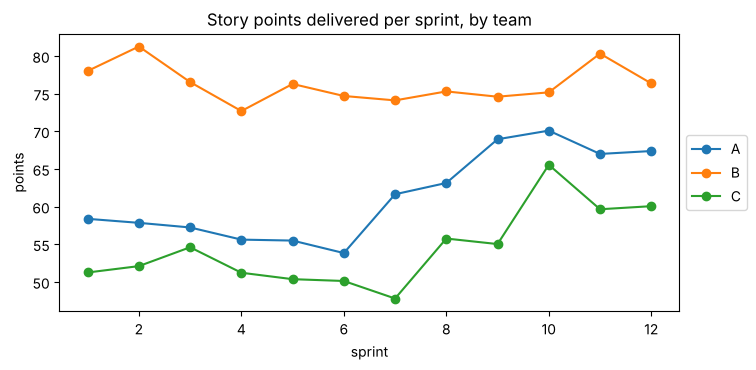

In [6]:
team_output.plot(marker='o', figsize=(8, 3.6))
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5)); plt.title('Story points delivered per sprint, by team'); plt.ylabel('points'); plt.show()

How do people spend their 80 hours? Is it on the work that creates value?

In [7]:
cols = ['core_work', 'design_meetings', 'cross_team_dependencies', 'review_mentoring', 'other']
share = (people_sprint[cols].sum() / people_sprint[cols].sum().sum() * 100).round(1)
share.rename('% of all hours')

core_work                  60.6
design_meetings            13.0
cross_team_dependencies    11.1
review_mentoring            7.6
other                       7.8
Name: % of all hours, dtype: float64

How long does a ticket take from start to done? *(median days; a sprint is 10 working days)*

In [8]:
tickets.groupby('team').agg(tickets=('ticket_id', 'count'), median_cycle_days=('cycle_days', 'median'),
                            share_missing_sprint=('missed_sprint', 'mean')).round(2)

,tickets,median_cycle_days,share_missing_sprint
team,,,
A,216,6.60,0.26
B,216,3.50,0.03
C,216,5.75,0.19


## 2. Why is output low in some places? (diagnostic)
The brief names four usual causes. We check each one.

**a) Are our best developers spending time on non-coding work?**

In [9]:
people_sprint['non_core_share'] = 1 - people_sprint.core_work / HOURS
by = people_sprint[people_sprint.role != 'QA'].groupby(['role', 'team']).non_core_share.mean().mul(100).round(0).unstack()
by.rename_axis('% of time NOT on core work')

team,A,B,C
% of time NOT on core work,,,
Developer,35.0,35.0,45.0
Senior Developer,42.0,58.0,42.0


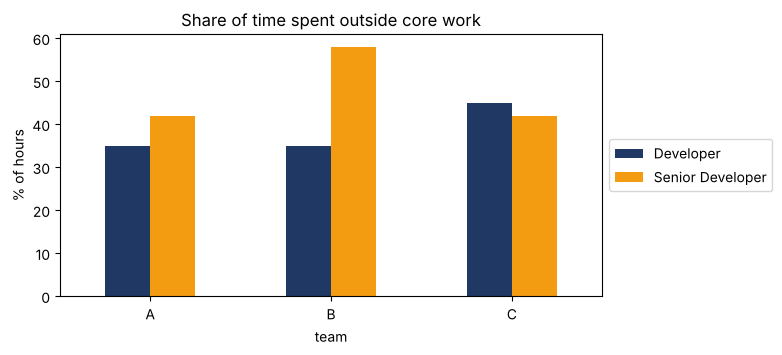

In [10]:
by.T.plot.bar(figsize=(7, 3.4), rot=0, color=['#1F3864', '#f39c12'])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5)); plt.title('Share of time spent outside core work'); plt.ylabel('% of hours'); plt.xlabel('team'); plt.show()

**b) Do new joiners contribute less? (onboarding)**

In [11]:
d = devs.copy()
d['experience'] = pd.cut(d.tenure_months, [-1, 6, 24, 1000], labels=['under 6 months', '6-24 months', 'over 24 months'])
d.groupby('experience', observed=True).agg(people_sprints=('points_done', 'count'),
                                          avg_points_per_sprint=('points_done', 'mean')).round(1)

,people_sprints,avg_points_per_sprint
experience,,
under 6 months,23,4.9
6-24 months,59,10.7
over 24 months,144,10.9


**c) Where does a ticket lose time: building, being blocked, or waiting for QA?**

In [12]:
lost = tickets.groupby('team')[['dev_days', 'blocked_days', 'qa_wait_days']].mean().round(1)
lost

,dev_days,blocked_days,qa_wait_days
team,,,
A,3.1,0.6,4.3
B,2.6,0.3,1.2
C,3.4,2.2,1.3


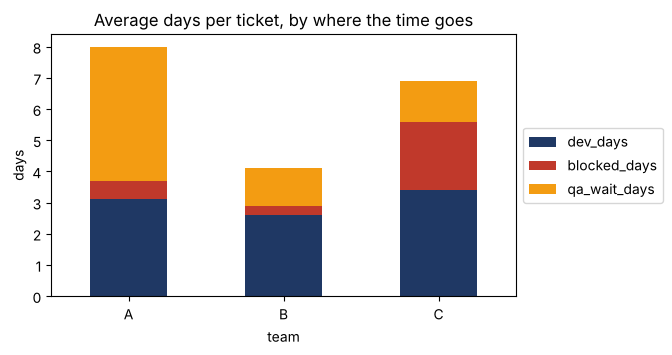

In [13]:
lost.plot.bar(stacked=True, figsize=(6, 3.4), rot=0, color=['#1F3864', '#c0392b', '#f39c12'])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5)); plt.title('Average days per ticket, by where the time goes'); plt.ylabel('days'); plt.xlabel('team'); plt.show()

**d) Which kinds of tickets miss the sprint most often?**

In [14]:
print('By dependency on another team:'); print(tickets.groupby('has_dependency').missed_sprint.mean().round(2).rename({0: 'no dependency', 1: 'has dependency'}).to_string())
print(); print('By size (story points):');  print(tickets.groupby('points').missed_sprint.mean().round(2).to_string())

By dependency on another team:
has_dependency
no dependency     0.09
has dependency    0.35

By size (story points):
points
1    0.08
2    0.10
3    0.13
5    0.29
8    0.48


## 3. Which tickets will miss the sprint? (predictive)
A basic model (logistic regression) learns from sprints 1-9, then predicts sprints 10-12, which it has never seen. That mirrors real use: predict upcoming work from history.
We compare it with a **baseline**: guessing that no ticket misses the sprint.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

t = tickets.copy()
t['is_bug'] = (t.issue_type == 'Bug').astype(int)
t = pd.concat([t, pd.get_dummies(t.team, prefix='team').astype(int)], axis=1)
features = ['points', 'has_dependency', 'is_bug', 'assignee_tenure', 'team_A', 'team_B', 'team_C']   # all known before the sprint starts
train, test = t[t.sprint <= 9], t[t.sprint >= 10]
print('Train tickets:', len(train), '| Test tickets (sprints 10-12):', len(test))
print('Share of tickets that missed the sprint (train):', round(train.missed_sprint.mean(), 2))

Train tickets: 486 | Test tickets (sprints 10-12): 162
Share of tickets that missed the sprint (train): 0.16


In [16]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[features], train.missed_sprint)
pred = model.predict(test[features])
actual = test.missed_sprint
caught = ((pred == 1) & (actual == 1)).sum()
print('Baseline accuracy (guess nothing misses):', round((actual == 0).mean(), 2))
print('Model accuracy                          :', round((pred == actual).mean(), 2))
print(f'Tickets that really missed the sprint: {actual.sum()}  |  caught by the model: {caught}  |  false alarms: {((pred == 1) & (actual == 0)).sum()}')

Baseline accuracy (guess nothing misses): 0.84
Model accuracy                          : 0.88
Tickets that really missed the sprint: 26  |  caught by the model: 11  |  false alarms: 5


Accuracy hides a lot when most tickets are fine. A more useful question for a leader: *if I only look at the 20% of tickets the model rates riskiest, how many of them really miss the sprint?*

In [17]:
test = test.copy()
test['risk_of_missing_sprint'] = model.predict_proba(test[features])[:, 1].round(2)
top = test.nlargest(int(len(test) * 0.2), 'risk_of_missing_sprint')
print(f'All tickets in test sprints that missed the sprint     : {test.missed_sprint.mean():.0%}')
print(f'Riskiest 20% (flagged by the model) that missed it     : {top.missed_sprint.mean():.0%}')

All tickets in test sprints that missed the sprint     : 16%
Riskiest 20% (flagged by the model) that missed it     : 47%


Which factors push the risk up? *(bigger bar = pushes the risk of missing the sprint up more)*

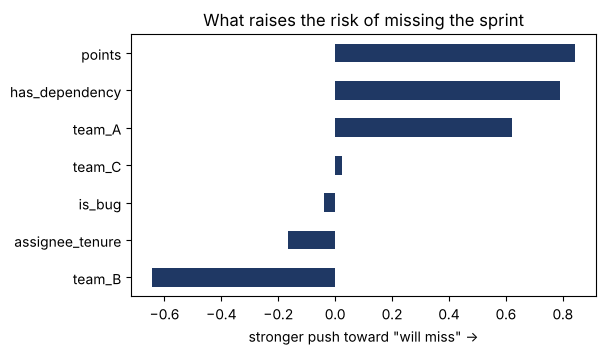

In [18]:
imp = pd.Series(model[-1].coef_[0], index=features).sort_values()
imp.plot.barh(figsize=(6, 3.4), color='#1F3864')
plt.title('What raises the risk of missing the sprint'); plt.xlabel('stronger push toward "will miss" ->'); plt.show()

## 4. What should leaders do? (prescriptive)
Three actions, each tied to a finding above. Every list is generated from the data.

**Action 1 - Protect the time of high-value developers.** Senior developers whose non-core time is well above their peers':

In [19]:
seniors = people_sprint[people_sprint.role == 'Senior Developer'].groupby('team').non_core_share.mean().mul(100).round(0)
seniors.rename('% of time outside core work')

team
A    42.0
B    58.0
C    42.0
Name: % of time outside core work, dtype: float64

In [20]:
benchmark = seniors.median()
flag = seniors[seniors > benchmark + 10]
for team, v in flag.items():
    print(f'Team {team}: senior developer spends {v:.0f}% of time outside core work (others: ~{benchmark:.0f}%). '
          f'Review who is pulling them into design sessions and clarify roles.')

Team B: senior developer spends 58% of time outside core work (others: ~42%). Review who is pulling them into design sessions and clarify roles.


**Action 2 - Check onboarding.** New joiners (under 6 months) producing well below their team's median:

In [21]:
latest = devs[devs.sprint == 12].copy()
team_median = latest.groupby('team').points_done.median()
latest['team_median'] = latest.team.map(team_median)
new = latest[(latest.tenure_months < 6)]
new[['person', 'tenure_months', 'points_done', 'team_median']].assign(
    pct_of_team_median=lambda x: (x.points_done / x.team_median * 100).round(0)).round(1)

,person,tenure_months,points_done,team_median,pct_of_team_median
77,A-Dev5,2.5,6.1,10.7,56.0
83,A-Dev6,2.5,6.0,10.7,56.0
256,C-Dev5,2.0,5.0,9.7,51.0
261,C-Dev6,2.0,5.1,9.7,53.0


**Action 3 - Remove the bottleneck.** Where do tickets wait longest, and for what?

In [22]:
worst = lost[['blocked_days', 'qa_wait_days']].stack().sort_values(ascending=False).head(2)
for (team, kind), days in worst.items():
    what = 'waiting for QA (add test capacity or test earlier)' if kind == 'qa_wait_days' else 'blocked by other teams (agree dependencies up front)'
    print(f'Team {team}: {days:.1f} days per ticket lost {what}')

Team A: 4.3 days per ticket lost waiting for QA (add test capacity or test earlier)
Team C: 2.2 days per ticket lost blocked by other teams (agree dependencies up front)


**Plus: the most at-risk tickets in the latest sprint (sprint 12, treated as still open), so leaders can act this week.**

In [23]:
current = test[test.sprint == 12]
current.sort_values('risk_of_missing_sprint', ascending=False)[
    ['ticket_id', 'team', 'assignee', 'issue_type', 'points', 'has_dependency', 'risk_of_missing_sprint']].head(10)

,ticket_id,team,assignee,issue_type,points,has_dependency,risk_of_missing_sprint
594,T595,A,A-Dev3,Bug,5,1,0.74
597,T598,A,A-Dev4,Bug,5,1,0.73
611,T612,A,A-Dev4,Bug,3,1,0.54
639,T640,C,C-Dev5,Bug,5,1,0.52
636,T637,C,C-Dev1,Story,5,1,0.51
607,T608,A,A-Senior,Bug,2,1,0.38
632,T633,C,C-Dev3,Story,8,0,0.38
644,T645,C,C-Dev1,Bug,8,0,0.35
598,T599,A,A-Dev3,Task,5,0,0.34
602,T603,A,A-Dev1,Task,5,0,0.33


## Summary for team leaders
- **Descriptive:** how much each team delivers, where the hours go, how long tickets take.
- **Diagnostic:** which of the usual causes (non-coding load, onboarding, blockers, QA queue) is visible in each team.
- **Predictive:** a short list of tickets likely to miss the sprint, before it is too late.
- **Prescriptive:** three concrete actions, each backed by a table above.

**Limits.** This shows where the problems are; it does not prove that a change will fix them. The data in this notebook is simulated;
run it on a real Jira and time-tracking export before drawing conclusions. Use it to support a conversation with the team, not to rank individuals.